# Практическая работа №1: Линейные дискретные системы и преобразование Фурье

Выполнил студент гр. 3383 Аненков Иван Сергеевич. Вариант №2.

## Цель работы

Изучить математическое описание линейных дискретных систем и дискретного преобразования Фурье (ДПФ) периодических последовательностей и последовательностей конечной длины.

## Основные теоретические положения

**Рекурсивное звено 2-го порядка** задаётся передаточной функцией

$$H(z)=\frac{b_0+b_1z^{-1}+b_2z^{-2}}{a_0+a_1z^{-1}+a_2z^{-2}},\qquad a_0=1,$$

которой соответствует разностное уравнение

$$y(n)=b_0x(n)+b_1x(n-1)+b_2x(n-2)-a_1y(n-1)-a_2y(n-2).$$

**Импульсная характеристика** $h(n)$ - реакция системы с нулевыми начальными условиями на единичный импульс $\delta(n)$. Для рекурсивного звена $h(n)$ бесконечна по длине (БИХ-система). Реакция на произвольное воздействие определяется сверткой

$$y(n)=\sum_{k}h(k)\,x(n-k).$$

Длина полной свёртки последовательностей длины $N_h$ и $N_x$ равна $N_h+N_x-1$.

**Нули и полюсы.** Нули - корни числителя, полюсы - корни знаменателя $H(z)$. Комплексное число $z=\mathrm{Re}\,z+j\,\mathrm{Im}\,z$ в показательной форме: $z=|z|e^{j\arg z}$. Звено устойчиво, если все полюсы лежат строго внутри единичной окружности.

**Частотные характеристики** получаются подстановкой $z=e^{j\hat\omega}$:

$$H(e^{j\hat\omega})=|H(e^{j\hat\omega})|\,e^{j\varphi(\hat\omega)},$$

где $|H|$ - амплитудно-частотная характеристика (АЧХ), $\varphi$ - фазочастотная характеристика (ФЧХ). Нормированная частота связана с частотой в герцах соотношением $\hat\omega=2\pi f/f_s$. Характеристики $2\pi$-периодичны по $\hat\omega$, основная полоса: $\hat\omega\in[-\pi,\pi]$ или $f\in[-f_s/2,\,f_s/2]$.

### Периодические последовательности и ДПФ (часть 2)

**ДПФ и ОДПФ** последовательности длины $N$:

$$X(k)=\sum_{n=0}^{N-1}x(n)\,e^{-j2\pi kn/N},\qquad x(n)=\frac1N\sum_{k=0}^{N-1}X(k)\,e^{j2\pi kn/N}.$$

**Периодическая последовательность** с периодом $N$ раскладывается в ряд Фурье с коэффициентами $c(k)=X(k)/N$. Амплитудный спектр — $|c(k)|$, фазовый — $\arg c(k)$. Для $x(n)=A\cos(2\pi k_0n/N+\varphi)$, $0<k_0<N/2$, спектр состоит из двух линий:

$$c(k_0)=\frac A2e^{j\varphi},\qquad c(-k_0)=c(N-k_0)=\frac A2e^{-j\varphi}.$$

**Шкалы.** Дискретное время $t_n=nT$, $T=1/f_s$; дискретное нормированное время $n=t_n/T$. Частота $k$-й гармоники $f_k=kf_s/N=k/(NT)$; дискретная нормированная частота — номер $k$ (эквивалентно $\hat\omega_k=2\pi k/N=2\pi f_k/f_s$).

**Восстановление аналогового сигнала** по отсчётам ДПФ:

$$x(t)=\frac1N\sum_{k=-N/2}^{N/2-1}X_a(k)\,e^{j2\pi kt/(NT)},\qquad X_a(k)=\begin{cases}X(N+k),&-N/2\le k\le-1,\\X(k),&0\le k\le N/2-1.\end{cases}$$

**Равенство Парсеваля:**

$$\sum_{n=0}^{N-1}|x(n)|^2=\frac1N\sum_{k=0}^{N-1}|X(k)|^2.$$

## Постановка задачи

Выполнить программную реализацию линейных дискретных систем, а также применить ДПФ для анализа периодических последовательностей и последовательностей конечной длины. Полученные результаты содержательно проинтерпретировать.

## Выполнение работы

### Часть 1.

#### Исходные данные варианта

Значения вычисляются по формулам из таблицы вариантов при $N_{var}=2$.

In [47]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.figsize': (9, 3.2), 'axes.grid': True, 'font.size': 10})

N_var = 2
b0 = 0.5 + 0.02 * N_var
b1 = b0 * (-1) ** (N_var + 1) * (0.9822 + 0.0178 * N_var)
b2 = b0 * (0.8 + 0.2 * (N_var % 5))
a0 = 1.0
a1 = (-1) ** N_var * (0.7778 + 0.025 * N_var)
a2 = 0.64 + 0.006 * N_var
N1 = N_var % 10 + 20
N2 = N_var % 10 + 30
fs = 1000 * N_var

b = np.array([b0, b1, b2])
a = np.array([a0, a1, a2])

print(f'b = {b}')
print(f'a = {a}')
print(f'N1 = {N1}, N2 = {N2}, fд = {fs} Гц')

b = [ 0.54     -0.549612  0.648   ]
a = [1.     0.8278 0.652 ]
N1 = 22, N2 = 32, fд = 2000 Гц


Передаточная функция варианта:

$$H(z)=\frac{0.54-0.5496z^{-1}+0.648z^{-2}}{1+0.8278z^{-1}+0.652z^{-2}}.$$

Разностное уравнение:

$$y(n)=0.54\,x(n)-0.5496\,x(n-1)+0.648\,x(n-2)-0.8278\,y(n-1)-0.652\,y(n-2).$$

#### Пункт 1.

> Вычислить импульсную характеристику длины $N_1$ по заданной передаточной функции с коэффициентами $b_i$, $a_k$ и построить её график. Записать аналитическую формулу импульсной характеристики рекурсивного звена 2-го порядка с учётом нулевых начальных условий. Пояснить, чему в действительности равна длина импульсной характеристики.

Импульсная характеристика длины $N_1$ вычисляется рекуррентно при нулевых начальных условиях: на вход подаётся $\delta(n)$, коэффициенты числителя дают вклад только при $n\le2$.

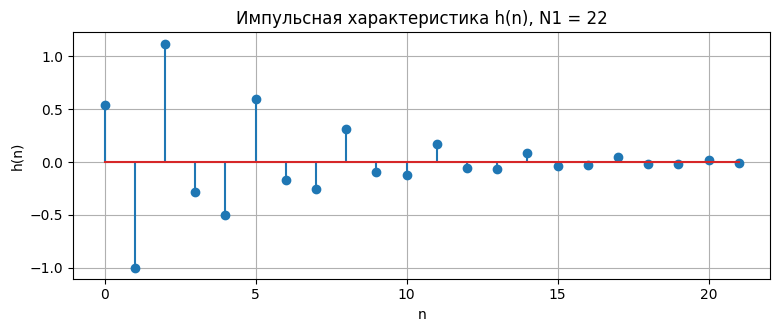



[ 0.54    -0.99662  1.12093 -0.2781  -0.50063  0.59574]


In [48]:
def impulse_response(b, a, N):
    h = np.zeros(N)
    for n in range(N):
        acc = b[n] if n < len(b) else 0.0
        for k in range(1, len(a)):
            if n - k >= 0:
                acc -= a[k] * h[n - k]
        h[n] = acc / a[0]
    return h

h = impulse_response(b, a, N1)
n1 = np.arange(N1)

plt.stem(n1, h)
plt.title('Импульсная характеристика h(n), N1 = %d' % N1)
plt.xlabel('n'); plt.ylabel('h(n)')
plt.show()
print('\n')
print(np.round(h[:6], 5))

**Аналитическая формула.** Полюсы $p_{1,2}=r\,e^{\pm j\theta}$, где $r=\sqrt{a_2}\approx0.8075$, $\theta\approx0.6713\pi$. Разложение на простейшие дроби:

$$H(z)=\frac{b_2}{a_2}+\frac{A}{1-p_1z^{-1}}+\frac{A^*}{1-p_1^*z^{-1}},\qquad \frac{b_2}{a_2}\approx0.9939,\quad A\approx-0.2269+0.8542j=0.8838\,e^{j\,1.8305}.$$

Обратное $z$-преобразование при нулевых начальных условиях даёт

$$h(n)=\frac{b_2}{a_2}\,\delta(n)+2|A|\,r^{n}\cos(\theta n+\arg A),\quad n\ge0,$$

то есть

$$h(n)\approx0.9939\,\delta(n)+1.7677\cdot0.8075^{n}\cos(2.109\,n+1.8305),\quad n\ge0.$$

Проверка формулы относительно рекуррентного расчёта:

In [49]:
p = np.roots(a)
p1 = p[np.imag(p) > 0][0]
q = 1 / p1
A = (b0 + b1 * q + b2 * q**2) / (1 - np.conj(p1) / p1)
c = b2 / a2

n_long = np.arange(200)
h_an = 2 * np.real(A * p1 ** n_long)
h_an[0] += c
h_rec = impulse_response(b, a, 200)

print('A =', A, ' |A| =', abs(A), ' arg A =', np.angle(A))
print('r =', abs(p1), ' theta/pi =', np.angle(p1) / np.pi)
print('Формулы совпадают:', np.allclose(h_an, h_rec))

A = (-0.22693251533742353+0.8542130056068431j)  |A| = 0.8838428737424128  arg A = 1.830461151398603
r = 0.807465169527454  theta/pi = 0.6713145607155663
Формулы совпадают: True


**Пояснение: длина импульсной характеристики.**

Рекурсивное звено имеет бесконечную импульсную характеристику (БИХ-система). Из аналитической формулы видно, что $h(n)$ затухает по закону $r^n$ с $r=\sqrt{a_2}\approx0.8075<1$, но в нуль не обращается. На графике также видно затухающие колебания.


Значение $N_1=22$  лишь задает длину используемого при свертке отрезка, за его пределами остаётся «хвост». В действительности длина импульсной характеристики бесконечна.

#### Пункт 2.


>Вычислить реакцию $y_1(n)$ по формуле свертки. В качестве воздействия $x(n)$ длины $N_2$ выбрать дискретный прямоугольный импульс:

$$x(n) = \begin{cases} 1, & 0 \leqslant n < int(N_2/2) \\ 0, & int(N_2/2) \leqslant n \leqslant N_2 - 1 \end{cases}$$

>где функция $int(t)$ — округление до ближайшего целого. Вывести графики воздействия и реакции. Пояснить:

> a. чему равна длина импульса $x$;

> b.  чему равна длина свёртки аналитически и по графику;

> с. почему её ограничивают до длины воздействия.

Воздействие — прямоугольный импульс длины $N_2=32$, единичный на отсчётах $0\le n<\mathrm{int}(N_2/2)=16$. Реакция $y_1(n)=\sum_k h(k)\,x(n-k)$  ограничивается до $N_2$ отсчётов.

Длина x: 32 , длина h: 22
Длина полной свёртки: 53 = N1 + N2 - 1 = 53


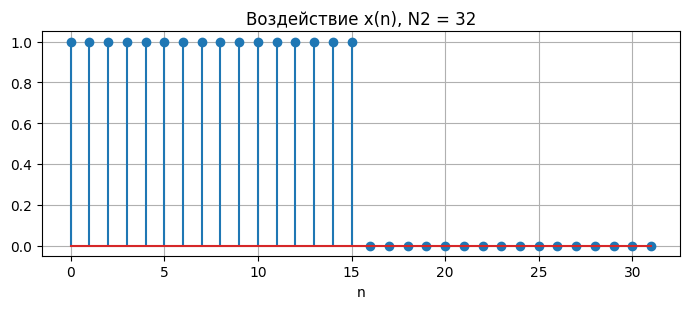

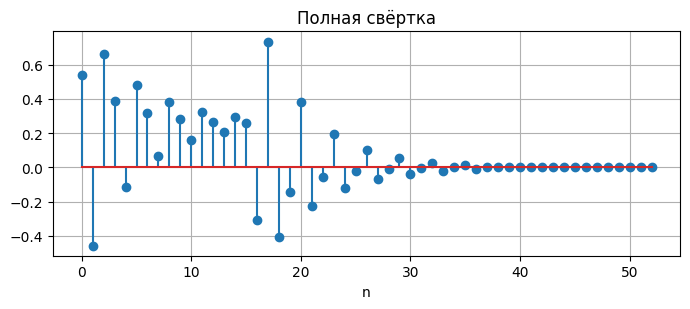

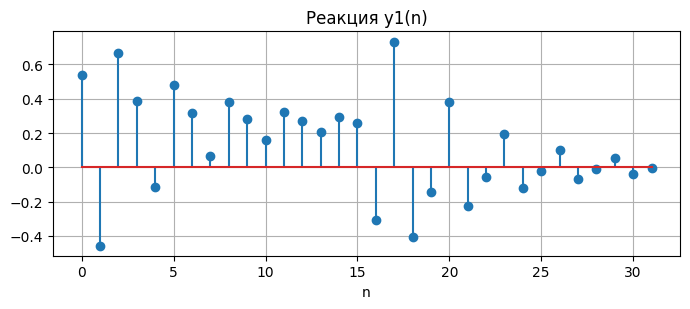

In [50]:
x = np.zeros(N2)
x[:int(round(N2 / 2))] = 1.0

y_full = np.convolve(x, h)
y1 = y_full[:N2]
n2 = np.arange(N2)

print('Длина x:', len(x), ', длина h:', len(h))
print('Длина полной свёртки:', len(y_full), '= N1 + N2 - 1 =', N1 + N2 - 1)

plt.figure(figsize=(7, 3.2))
plt.stem(n2, x); plt.title('Воздействие x(n), N2 = %d' % N2); plt.xlabel('n')
plt.tight_layout(); plt.show()

plt.figure(figsize=(7, 3.2))
plt.stem(np.arange(len(y_full)), y_full); plt.title('Полная свёртка'); plt.xlabel('n')
plt.tight_layout(); plt.show()

plt.figure(figsize=(7, 3.2))
plt.stem(n2, y1); plt.title('Реакция y1(n)'); plt.xlabel('n')
plt.tight_layout(); plt.show()

**Пояснения**

**a. Длина импульса $x$.** Последовательность $x(n)$ имеет длину $N_2=32$ отсчёта. Единичное значение принимают $\mathrm{int}(N_2/2)=16$ отсчётов ($n=0,\dots,15$), остальные 16 отсчётов ($n=16,\dots,31$) равны нулю. То длительность самого импульса - 16 отсчётов.

**b. Длина свёртки.** Аналитически длина свертки двух последовательностей длин $N_1$ и $N_2$ равна:

$$L=N_1+N_2-1=22+32-1=53.$$

По графику полной свёртки ось $n$ проходит от $0$ до $52$, т. е. 53 отсчёта.

**c. Почему свёртку ограничивают до длины воздействия.**

 Реакция БИХ-звена на конечное воздействие бесконечна: после окончания импульса она продолжает затухать. Реакцию ограничивают, чтобы ее длина совпадала с длиной воздействия, то есть, на каждый входной отсчёт - один выходной.

#### Пункт 3.

> Вычислить реакцию $y_2(n)$ по разностному уравнению. Задать воздействие $x(n)$ из п. 2. Вывести графики воздействия и реакции. Сравнить графики реакций $y_1(n)$ и $y_2(n)$. Записать разностное уравнение рекурсивного звена 2-го порядка с заданными коэффициентами. Пояснить, чему равны длины воздействия и реакции.

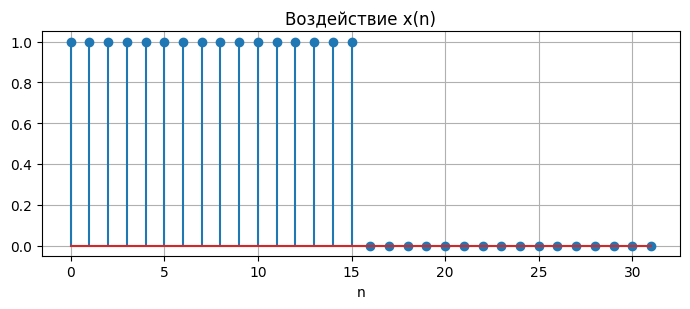

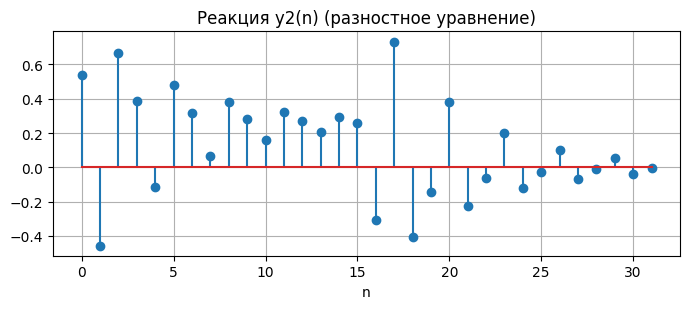

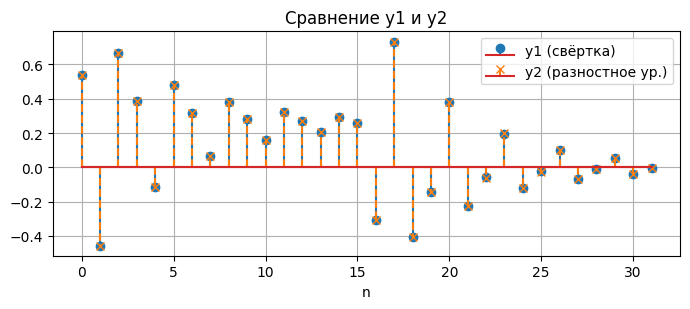


 Расхождение: max |y1 - y2| при n >= N1: 0.007193398170079468


In [51]:
def difference_eq(b, a, x):
    y = np.zeros(len(x))
    for n in range(len(x)):
        acc = 0.0
        for k in range(len(b)):
            if n - k >= 0:
                acc += b[k] * x[n - k]
        for k in range(1, len(a)):
            if n - k >= 0:
                acc -= a[k] * y[n - k]
        y[n] = acc / a[0]
    return y

y2 = difference_eq(b, a, x)

plt.figure(figsize=(7, 3.2))
plt.stem(n2, x); plt.title('Воздействие x(n)'); plt.xlabel('n')
plt.tight_layout(); plt.show()

plt.figure(figsize=(7, 3.2))
plt.stem(n2, y2); plt.title('Реакция y2(n) (разностное уравнение)'); plt.xlabel('n')
plt.tight_layout(); plt.show()

plt.figure(figsize=(7, 3.2))
plt.stem(n2, y1, linefmt='C0-', markerfmt='C0o', label='y1 (свёртка)')
plt.stem(n2, y2, linefmt='C1--', markerfmt='C1x', label='y2 (разностное ур.)')
plt.legend(); plt.title('Сравнение y1 и y2'); plt.xlabel('n')
plt.tight_layout(); plt.show()

diff = np.abs(y1 - y2)
print('\n Расхождение: max |y1 - y2| при n >= N1:', diff[N1:].max())

**Разностное уравнение рекурсивного звена с заданными коэффициентами:**

$$y(n)=0.54\,x(n)-0.5496\,x(n-1)+0.648\,x(n-2)-0.8278\,y(n-1)-0.652\,y(n-2).$$


**Сравнение $y_1(n)$ и $y_2(n)$.** На интервале $0\le n\le N_1-1=21$ графики совпадают, поскольку в свёртке при $n\le21$ используются только отсчёты $h(0),\dots,h(n)$, не затронутые усечением. Начиная с $n=22$ появляется небольшое расхождение (максимум $7.2\cdot10^{-3}$), так как  $y_1$ вычислена по $h(n)$, усечённой до $N_1=22$ отсчётов, а $y_2$ учитывает всю импульсную характеристику.

**Длины воздействия и реакции.**
- Длина воздействия $x(n)$: $N_2=32$ отсчёта (из них 16 ненулевых).
- Реакция $y_2(n)$ вычисляется рекурсивно на тех же отсчётах, на которых задано воздействие, поэтому её длина также $N_2=32$; реакция $y_1(n)$ после ограничения тоже содержит 32 отсчёта (полная свёртка - 53).
- Физически реакция БИХ-звена на конечное воздействие бесконечна (затухающие колебания продолжаются после окончания импульса), поэтому длина реакции - это длина выбранного интервала наблюдения.

#### Пункт 4.

> Вычислить нули и полюсы передаточной функции в алгебраической и показательной формах и пояснить связь между ними. Выразить значение аргумента полюса и нуля относительно $\pi$. Представить передаточную функцию в виде произведения простейших множителей с нулями и полюсами в показательной форме.

Нули - корни $b_0z^2+b_1z+b_2$, полюсы - корни $z^2+a_1z+a_2$ (числитель и знаменатель умножены на $z^2$).

In [52]:
zeros = np.roots(b)
poles = np.roots(a)

def show(name, roots):
    for r_ in roots:
        print(f'{name}: {r_.real:+.4f} {r_.imag:+.4f}j  =  {abs(r_):.4f} * exp(j * {np.angle(r_)/np.pi:+.4f} * pi)')

show('нуль  ', zeros)
show('полюс ', poles)
print('Проверка |z|: sqrt(b2/b0) =', np.sqrt(b2 / b0), ', sqrt(a2) =', np.sqrt(a2))

нуль  : +0.5089 +0.9701j  =  1.0954 * exp(j * +0.3462 * pi)
нуль  : +0.5089 -0.9701j  =  1.0954 * exp(j * -0.3462 * pi)
полюс : -0.4139 +0.6933j  =  0.8075 * exp(j * +0.6713 * pi)
полюс : -0.4139 -0.6933j  =  0.8075 * exp(j * -0.6713 * pi)
Проверка |z|: sqrt(b2/b0) = 1.0954451150103324 , sqrt(a2) = 0.807465169527454


**Алгебраическая форма.** Корни квадратных уравнений:

$$z_{1,2}=\frac{-b_1\pm\sqrt{b_1^2-4b_0b_2}}{2b_0},\quad D=b_1^2-4b_0b_2=-1.0976<0\ \Rightarrow\ z_{1,2}=\frac{0.5496\pm1.0477\,j}{1.08}=0.5089\pm0.9701\,j,$$

$$p_{1,2}=\frac{-a_1\pm\sqrt{a_1^2-4a_2}}{2},\quad D=a_1^2-4a_2=-1.9227<0\ \Rightarrow\ p_{1,2}=\frac{-0.8278\pm1.3866\,j}{2}=-0.4139\pm0.6933\,j.$$

**Показательная форма:**

$$z_{1,2}=1.0954\,e^{\pm j\,0.3462\pi},\qquad p_{1,2}=0.8075\,e^{\pm j\,0.6713\pi}.$$

**Аргументы относительно $\pi$:** для нулей $\arg z_{1,2}=\pm0.3462\pi\approx\pm62.3^\circ$; для полюсов $\arg p_{1,2}=\pm0.6713\pi\approx\pm120.8^\circ$.

**Связь форм.** Переход от алгебраической формы $x+jy$ к показательной: $|z|=\sqrt{x^2+y^2}$, $\arg z=\operatorname{arctg}(y/x)$. Обратный переход: $x=|z|\cos\arg z$, $y=|z|\sin\arg z$. Коэффициенты вещественны, поэтому корни образуют комплексно-сопряжённые пары с  равными модулями и противоположными аргументами. Модули связаны коэффициентами: $|z_{1,2}|=\sqrt{b_2/b_0}=1.0954$ (произведение сопряжённых корней $z_1z_2=b_2/b_0$), $|p_{1,2}|=\sqrt{a_2}=0.8075$.

**Передаточная функция в виде произведения простейших множителей:**

$$H(z)=b_0\,\frac{\left(1-1.0954\,e^{j0.3462\pi}z^{-1}\right)\left(1-1.0954\,e^{-j0.3462\pi}z^{-1}\right)}{\left(1-0.8075\,e^{j0.6713\pi}z^{-1}\right)\left(1-0.8075\,e^{-j0.6713\pi}z^{-1}\right)},\quad b_0=0.54.$$

#### Пункт 5.

Изобразить карту нулей и полюсов. Пояснить:

> a. является ли рекурсивное звено устойчивым;

> b. совпадают ли значения нулей и полюсов с вычисленными в п. 4.

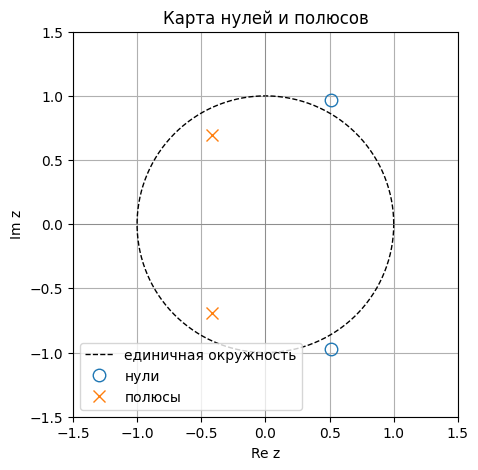

Максимум |полюс|: 0.8074651695274541 < 1 — устойчиво: True
Нули совпадают: True
Полюсы совпадают: True


In [53]:
from scipy.signal import tf2zpk
z_chk, p_chk, k_chk = tf2zpk(b, a)

#print(z_chk)
#print(p_chk)

fig, ax = plt.subplots(figsize=(5, 5))
t = np.linspace(0, 2 * np.pi, 400)
ax.plot(np.cos(t), np.sin(t), 'k--', lw=1, label='единичная окружность')
ax.plot(zeros.real, zeros.imag, 'o', mfc='none', ms=9, label='нули')
ax.plot(poles.real, poles.imag, 'x', ms=9, label='полюсы')
ax.axhline(0, color='gray', lw=.5); ax.axvline(0, color='gray', lw=.5)
ax.set_aspect('equal'); ax.set_xlim(-1.5, 1.5); ax.set_ylim(-1.5, 1.5)
ax.set_xlabel('Re z'); ax.set_ylabel('Im z'); ax.set_title('Карта нулей и полюсов')
ax.legend(loc='lower left'); plt.show()

print('Максимум |полюс|:', np.max(np.abs(poles)), '< 1 — устойчиво:', np.max(np.abs(poles)) < 1)
print('Нули совпадают:', np.allclose(np.sort_complex(z_chk), np.sort_complex(zeros)))
print('Полюсы совпадают:', np.allclose(np.sort_complex(p_chk), np.sort_complex(poles)))

**Пояснения.**

**a. Устойчивость.** Рекурсивное звено устойчиво, если все полюсы лежат строго внутри единичной окружности. Здесь $|p_{1,2}|=\sqrt{a_2}=0.8075<1$, поэтому звено **устойчиво**. Нули лежат вне единичной окружности ($|z|=1.095>1$), но на на устойчивость это не влияет.

**b. Совпадение с п. 4.** Положения нулей ($0.5089\pm0.9701j$) и полюсов ($-0.4139\pm0.6933j$) на карте совпадают со значениями, вычисленными в п. 4.

#### Пункт 6.

Вычислить амплитудно-частотную (АЧХ) и фазочастотную (ФЧХ) характеристики в шкале нормированных частот $\hat\omega$ и вывести их графики. Пояснить:

  >a. чему равны границы основной полосы частот;

  >b. соответствие между картой нулей и полюсов и видом АЧХ;

  >c. какому значению АЧХ соответствует скачок на $\pi$, если он имеется;

  >d. какие частотные составляющие воздействия, низкие или высокие, оказались преимущественно подавленными в реакции.


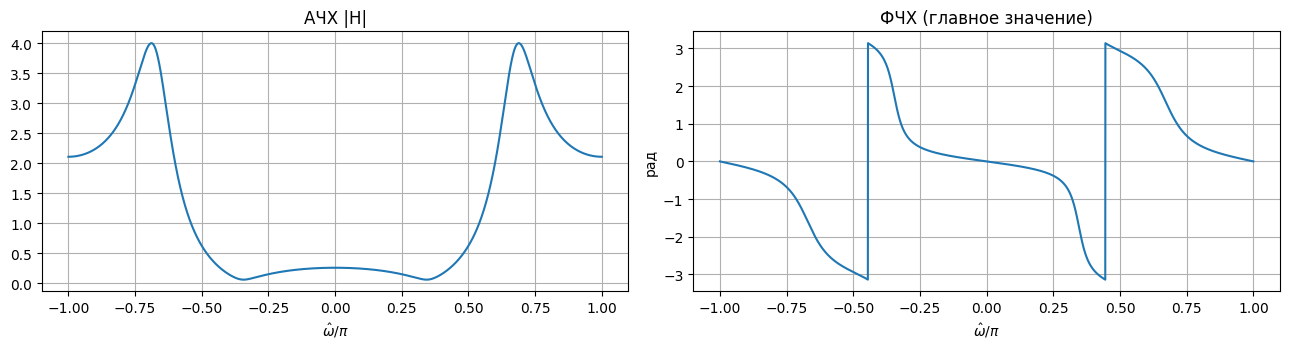

|H(0)| = 0.2574,  |H(pi)| = 2.1082
max|H| = 4.0033 при w/pi = 0.6885
min|H| = 0.0586 при w/pi = 0.3433
Скачки ФЧХ > pi при w/pi = [-0.4453  0.4448]
|H|<1 при w/pi от 0 до 0.5405


In [54]:
w = np.linspace(-np.pi, np.pi, 4097)
E = np.exp(-1j * w)
Hw = (b0 + b1 * E + b2 * E**2) / (a0 + a1 * E + a2 * E**2)
mag = np.abs(Hw)
phase = np.angle(Hw)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].plot(w / np.pi, mag); ax[0].set_title('АЧХ |H|'); ax[0].set_xlabel(r'$\hat\omega/\pi$')
ax[1].plot(w / np.pi, phase); ax[1].set_title('ФЧХ (главное значение)'); ax[1].set_xlabel(r'$\hat\omega/\pi$')
ax[1].set_ylabel('рад')
plt.tight_layout(); plt.show()

i0 = np.argmin(np.abs(w)); ipi = len(w) - 1
pos = w >= 0
print(f'|H(0)| = {mag[i0]:.4f},  |H(pi)| = {mag[ipi]:.4f}')
print(f'max|H| = {mag.max():.4f} при w/pi = {abs(w[np.argmax(mag)])/np.pi:.4f}')
print(f'min|H| = {mag.min():.4f} при w/pi = {abs(w[np.argmin(mag)])/np.pi:.4f}')
jumps = np.where(np.abs(np.diff(phase)) > np.pi)[0]
print('Скачки ФЧХ > pi при w/pi =', np.round(w[jumps] / np.pi, 4))
print('|H|<1 при w/pi от 0 до', np.round(w[pos][np.argmax(mag[pos] >= 1)] / np.pi, 4))

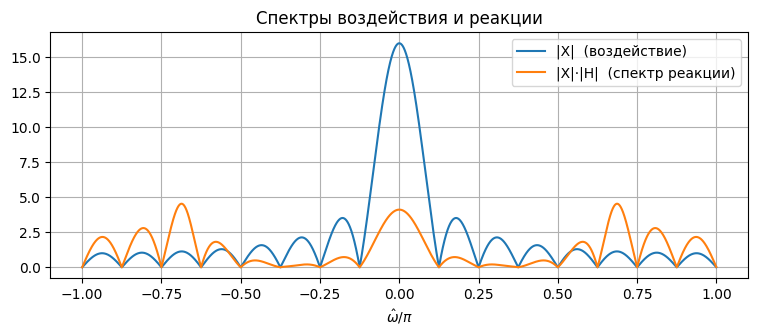

In [55]:
Nfft = 4096
X = np.fft.fftshift(np.fft.fft(x, Nfft))
wf = np.fft.fftshift(np.fft.fftfreq(Nfft)) * 2 * np.pi
Hf = np.interp(wf, w, mag)

plt.plot(wf / np.pi, np.abs(X), label='|X|  (воздействие)')
plt.plot(wf / np.pi, np.abs(X) * Hf, label='|X|·|H|  (спектр реакции)')
plt.xlabel(r'$\hat\omega/\pi$'); plt.legend(); plt.title('Спектры воздействия и реакции')
plt.show()

In [56]:
w_c = w[pos][np.argmax(mag[pos] >= 1)]
wf2 = np.fft.fftfreq(4096) * 2 * np.pi
low = np.abs(wf2) < w_c
X2 = np.fft.fft(x, 4096)
Y2 = np.fft.fft(y2, 4096)
print(f'w_c = {w_c/np.pi:.3f} pi')
print(f'Доля энергии воздействия x в полосе |w| < w_c: {np.sum(np.abs(X2[low])**2)/np.sum(np.abs(X2)**2):.3f}')
print(f'Доля энергии реакции y2 в полосе |w| < w_c:    {np.sum(np.abs(Y2[low])**2)/np.sum(np.abs(Y2)**2):.3f}')

w_c = 0.541 pi
Доля энергии воздействия x в полосе |w| < w_c: 0.981
Доля энергии реакции y2 в полосе |w| < w_c:    0.318


**Пояснения.**

**a. Границы основной полосы частот.** $\hat\omega\in[-\pi,\pi]$ (для вещественных сигналов достаточно $[0,\pi]$: АЧХ чётна, ФЧХ нечётна). За пределами этой полосы характеристики периодически повторяются с периодом $2\pi$. Граница $\hat\omega=\pi$ соответствует половине частоты дискретизации.

**b. Соответствие карты нулей и полюсов виду АЧХ.** Модуль частотной характеристики — отношение произведений расстояний от точки $e^{j\hat\omega}$ на единичной окружности до нулей и до полюсов:

$$|H(e^{j\hat\omega})|=|b_0|\,\frac{|e^{j\hat\omega}-z_1|\,|e^{j\hat\omega}-z_2|}{|e^{j\hat\omega}-p_1|\,|e^{j\hat\omega}-p_2|}.$$

- Полюс $p_1=0.807\,e^{j0.671\pi}$ расположен близко к окружности (расстояние до неё $1-0.807\approx0.19$). При приближении точки $e^{j\hat\omega}$ к его аргументу знаменатель уменьшается, и на АЧХ возникает максимум $|H|_{\max}=4.00$ при $\hat\omega\approx0.689\pi$ (расстояние до $p_1$ в этой точке $0.20$, до $p_2$ — $1.53$).
- Нуль $z_1=1.095\,e^{j0.346\pi}$ расположен вблизи окружности (расстояние до неё $0.095$). При $\hat\omega\approx0.343\pi$ расстояние до нуля минимально ($0.096$), и на АЧХ возникает глубокий провал $|H|_{\min}=0.059$. Полного обнуления нет, так как нуль не лежит на самой окружности.
- Для $\hat\omega<0$ картина зеркальна (сопряженные нуль и полюс).

**c. Скачок на $\pi$.** Скачок ФЧХ на $\pi$ возможен только там, где АЧХ обращается в нуль, т. е. где нуль лежит на единичной окружности (при переходе через такую точку $H$ меняет знак). В данном звене нулей на окружности нет ($|z_{1,2}|=1.095$), минимум АЧХ равен $0.0586\ne0$, поэтому скачка на $\pi$ нет и ФЧХ непрерывна.

**d. Подавленные составляющие.** АЧХ меньше единицы на низких частотах ($|H|<1$ при $|\hat\omega|<0.54\pi$; $|H(0)|=0.2574$) и больше единицы на высоких ($|H(\pi)|=2.1082$, максимум $4.00$ при $0.689\pi$). Спектр прямоугольного импульса сосредоточен около нулевой частоты: в полосе $|\hat\omega|<0.54\pi$ лежит около $98\%$ энергии воздействия, а в реакции - около $32\%$ (расчёт в ячейке выше). Следовательно, в реакции преимущественно подавлены **низкие** частоты, высокочастотные составляющие усилены.

#### Пункт 7.

Вычислить АЧХ и ФЧХ в шкале частот $f$ (Гц) при заданной частоте дискретизации $f_s$ и вывести их графики. Пояснить:

> a. чему равны границы основной полосы частот;

> b. соответствие между частотами $\hat\omega$ и $f$.

$f=\hat\omega f_s/(2\pi)$, $f_s=2000$ Гц.

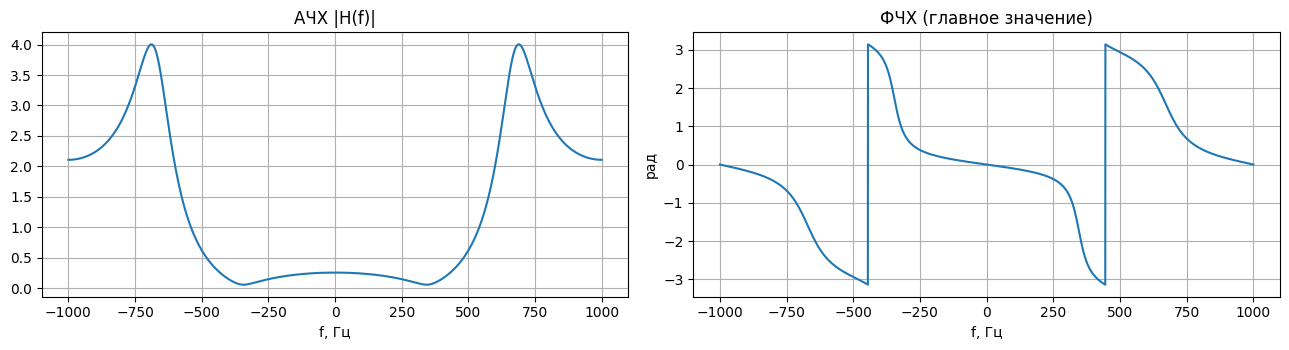


Максимум АЧХ при f = 688.5 Гц

Минимум АЧХ при f = 343.3 Гц


In [57]:
f = w * fs / (2 * np.pi)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].plot(f, mag); ax[0].set_title('АЧХ |H(f)|'); ax[0].set_xlabel('f, Гц')
ax[1].plot(f, phase); ax[1].set_title('ФЧХ (главное значение)'); ax[1].set_xlabel('f, Гц'); ax[1].set_ylabel('рад')
plt.tight_layout(); plt.show()

print(f'\nМаксимум АЧХ при f = {abs(f[np.argmax(mag)]):.1f} Гц')
print(f'\nМинимум АЧХ при f = {abs(f[np.argmin(mag)]):.1f} Гц')

**Пояснения.**

**a. Границы основной полосы частот.** $f\in[-f_s/2,\,f_s/2]=[-1000,\,1000]$ Гц (для вещественных сигналов $[0,\,1000]$ Гц). За пределами полосы характеристики периодически повторяются с периодом $f_s=2000$ Гц.

**b. Соответствие между $\hat\omega$ и $f$.** Связь линейная: $f=\hat\omega f_s/(2\pi)$, $\hat\omega=2\pi f/f_s$. Форма АЧХ и ФЧХ не меняется, масштабируется только горизонтальная ось.

### Часть 2.

#### Исходные данные варианта (часть 2)

$N=64$,

$f_s=2000\cdot(N_{var}\bmod5+1)=6000$ Гц,

$T=1/f_s$,

$A_1=1+0.01N_{var}=1.02$,

$A_2=2A_1=2.04$,

$f_1=f_s/8=750$ Гц,

 $f_2=1.5f_1=1125$ Гц.

In [58]:
N = 64
fd = 2000 * (N_var % 5 + 1)
T = 1 / fd
A1 = 1 + 0.01 * N_var
A2 = 2 * A1
f1 = fd / 8
f2 = 1.5 * f1
n_idx = np.arange(N)

print(f'N = {N}, fд = {fd} Гц, T = {T*1e6:.2f} мкс\n')
print(f'A1 = {A1}, A2 = {A2}, f1 = {f1} Гц, f2 = {f2} Гц\n')
print(f'Номера гармоник: k1 = f1*N/fд = {f1*N/fd}, k2 = f2*N/fd = {f2*N/fd}\n')
print(f'Период последовательности N*T = {N*T*1e3:.3f} мс, шаг по частоте fд/N = {fd/N} Гц')

N = 64, fд = 6000 Гц, T = 166.67 мкс

A1 = 1.02, A2 = 2.04, f1 = 750.0 Гц, f2 = 1125.0 Гц

Номера гармоник: k1 = f1*N/fд = 8.0, k2 = f2*N/fd = 12.0

Период последовательности N*T = 10.667 мс, шаг по частоте fд/N = 93.75 Гц


#### Пункт 1.

>Вычислить амплитудный и фазовый спектры периодической последовательности $x(n)$ с периодом $N$: $x(nT)=A_1\cos(2\pi f_1nT+\pi/4)+A_2\cos(2\pi f_2nT+\pi/8)$. Вывести графики последовательности $x(n)$ на периоде $N$ в шкале дискретного и дискретного нормированного времени.

Спектры вычисляются и выводятся в п. 3; здесь строятся графики последовательности на периоде.

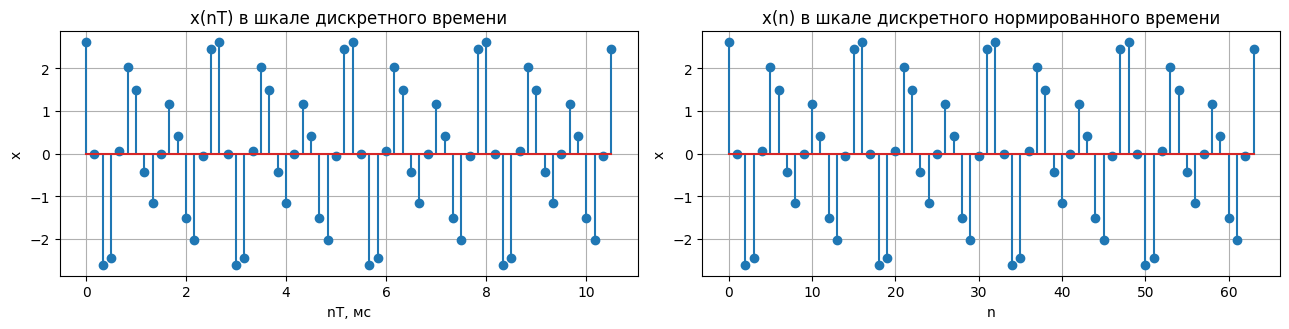

Период последовательности 16 отсчётов, x(n+16) = x(n): True


In [59]:
xs = A1 * np.cos(2 * np.pi * f1 * n_idx * T + np.pi / 4) + A2 * np.cos(2 * np.pi * f2 * n_idx * T + np.pi / 8)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
ax[0].stem(n_idx * T * 1e3, xs)
ax[0].set_title('x(nT) в шкале дискретного времени'); ax[0].set_xlabel('nT, мс'); ax[0].set_ylabel('x')
ax[1].stem(n_idx, xs)
ax[1].set_title('x(n) в шкале дискретного нормированного времени'); ax[1].set_xlabel('n'); ax[1].set_ylabel('x')
plt.tight_layout(); plt.show()

k_idx = np.arange(N)
W = np.exp(-2j * np.pi * np.outer(k_idx, n_idx) / N)
Xk = W @ xs
print('Период последовательности 16 отсчётов, x(n+16) = x(n):', np.allclose(xs[16:], xs[:-16]))

**Пояснение к графикам.** Шкалы отличаются только масштабом оси абсцисс: дискретное время $t_n=nT$ и дискретное нормированное время $n=t_n/T$ - безразмерный номер отсчёта.

#### Пункт 2.

> Вычислить ОДПФ от ДПФ последовательности $x(n)$ и вывести график полученной последовательности в шкале дискретного нормированного времени.


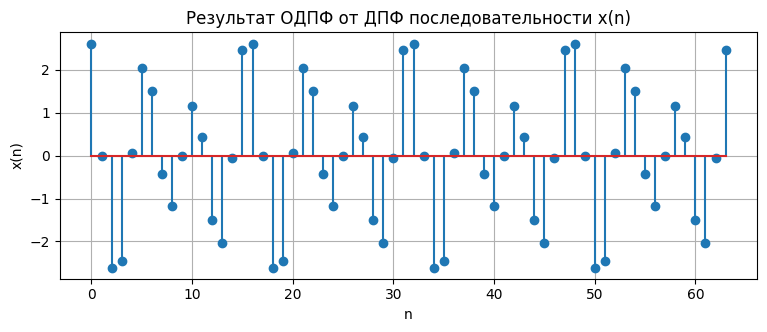

max |Im(x_back)| = 2.770401696440217e-14
max |x_back - x| = 2.1760371282653068e-14


In [60]:
x_back = (np.conj(W) @ Xk) / N

plt.stem(n_idx, x_back.real)
plt.title('Результат ОДПФ от ДПФ последовательности x(n)')
plt.xlabel('n'); plt.ylabel('x(n)')
plt.show()
#print(x_back)
#print(xs)
print('max |Im(x_back)| =', np.max(np.abs(x_back.imag)))
print('max |x_back - x| =', np.max(np.abs(x_back.real - xs)))

**Пояснение.** ДПФ переводит $x(n)$ в частотную область, ОДПФ — обратно. Мнимая часть результата пренебрежимо мала ($2.8\cdot10^{-14}$), а сама последовательность совпадает с исходной $x(n)$ с точностью $2.2\cdot10^{-14}$ — это машинная погрешность. Следовательно, ДПФ и ОДПФ — взаимно обратные преобразования.



#### Пункт 3.

Вычислить амплитудный и фазовый спектры последовательности $x(n)$ и вывести их графики в шкалах дискретных нормированных и абсолютных частот. Пояснить:

> a. связь дискретного нормированного времени с дискретным временем;

> b. связь частоты $f$ (Гц) с дискретной нормированной частотой;

> c. вид амплитудного и фазового спектров.

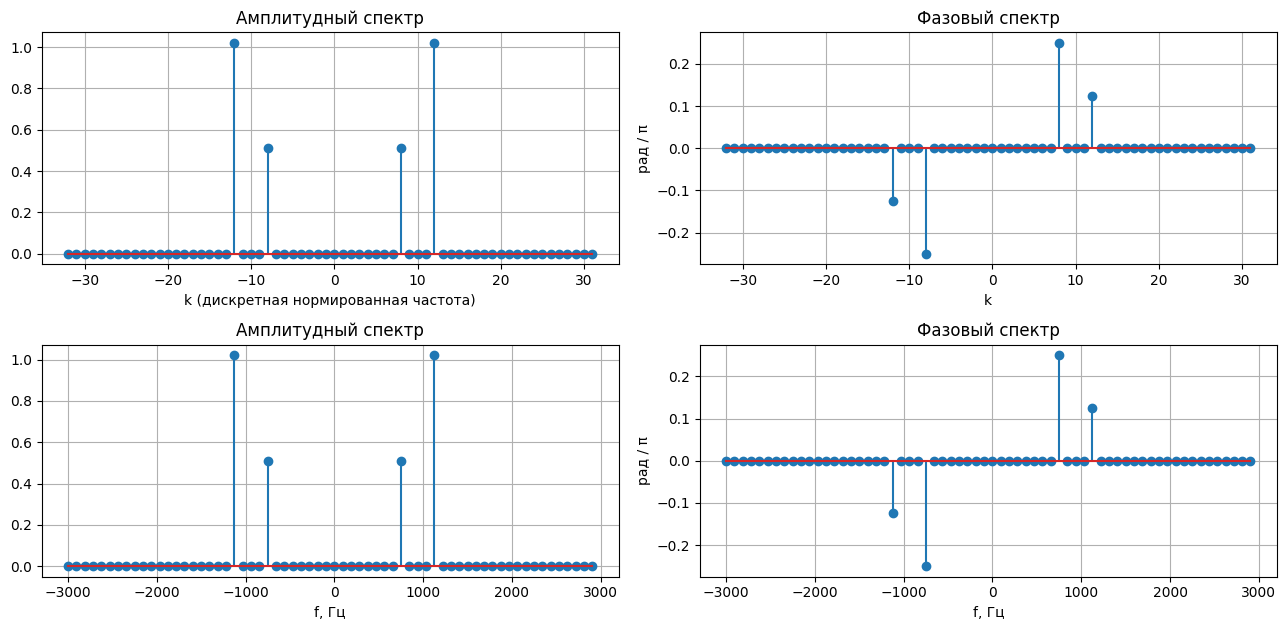


k = -12, f = -1125.00 Гц, |c| = 1.0200, arg c = -0.1250 π

k =  -8, f =  -750.00 Гц, |c| = 0.5100, arg c = -0.2500 π

k =  +8, f =  +750.00 Гц, |c| = 0.5100, arg c = +0.2500 π

k = +12, f = +1125.00 Гц, |c| = 1.0200, arg c = +0.1250 π


In [61]:
c = Xk / N
k_c = np.arange(-N // 2, N // 2)
c_c = np.fft.fftshift(c)
amp = np.abs(c_c)
ph = np.where(amp > 1e-9, np.angle(c_c), 0.0)
f_k = k_c * fd / N

fig, ax = plt.subplots(2, 2, figsize=(13, 6.4))
ax[0, 0].stem(k_c, amp); ax[0, 0].set_title('Амплитудный спектр'); ax[0, 0].set_xlabel('k (дискретная нормированная частота)')
ax[0, 1].stem(k_c, ph / np.pi); ax[0, 1].set_title('Фазовый спектр'); ax[0, 1].set_xlabel('k'); ax[0, 1].set_ylabel('рад / π')
ax[1, 0].stem(f_k, amp); ax[1, 0].set_title('Амплитудный спектр'); ax[1, 0].set_xlabel('f, Гц')
ax[1, 1].stem(f_k, ph / np.pi); ax[1, 1].set_title('Фазовый спектр'); ax[1, 1].set_xlabel('f, Гц'); ax[1, 1].set_ylabel('рад / π')
plt.tight_layout(); plt.show()

for kk, ff, aa, pp in zip(k_c, f_k, amp, ph):
    if aa > 1e-9:
        print(f'\nk = {kk:+3d}, f = {ff:+8.2f} Гц, |c| = {aa:.4f}, arg c = {pp/np.pi:+.4f} π')

**Пояснения.**

**a. Дискретное нормированное время и дискретное время.** Дискретное время - моменты отсчётов $t_n=nT$, где $T=1/f_s=166.7$ мкс. Дискретное нормированное время — безразмерный номер отсчёта $n=t_n/T$, т. е. время, выраженное в числе периодов дискретизации, обратная связь $t_n=nT$.

**b. Связь частоты $f$ (Гц) с дискретной нормированной частотой.** Дискретная нормированная частота - номер гармоники $k$ (в шкале $\hat\omega$: $\hat\omega_k=2\pi k/N$). Частота $k$-й гармоники $f_k=k\,f_s/N=k/(NT)$, т. е. шаг по оси частот $f_s/N=93.75$ Гц; обратно $k=fN/f_s$ и $\hat\omega_k=2\pi f_k/f_s$.

| гармоника | $f$, Гц | $k$ | $\hat\omega_k$ |
|---|---|---|---|
| $f_1$ | 750 | 8 | $\pi/4$ |
| $f_2$ | 1125 | 12 | $3\pi/8$ |

**c. Вид амплитудного и фазового спектров.** Спектры дискретные: ненулевые линии только при $k=\pm8$ и $k=\pm12$ (частоты $\pm750$ и $\pm1125$ Гц), на остальных $k$ амплитуда равна нулю. Амплитуды линий $A_1/2=0.51$ и $A_2/2=1.02$ - половины амплитуд гармоник, так как косинус делится поровну между положительной и отрицательной частотами.

Фазы: $+\pi/4$ при $k=8$ и $+\pi/8$ при $k=12$; при отрицательных $k$ те же значения с обратным знаком ($-\pi/4$, $-\pi/8$), амплитудный спектр четный, а фазовый нечетный.


#### Пункт 4. ДПФ конечной последовательности и амплитудный спектр периодической

> Вычислить ДПФ конечной последовательности $x(n)$ длины $N$. Вывести графики в шкале дискретных нормированных частот модуля ДПФ конечной последовательности и амплитудного спектра периодической последовательности. Пояснить связь модуля ДПФ конечной последовательности с амплитудным спектром периодической последовательности.

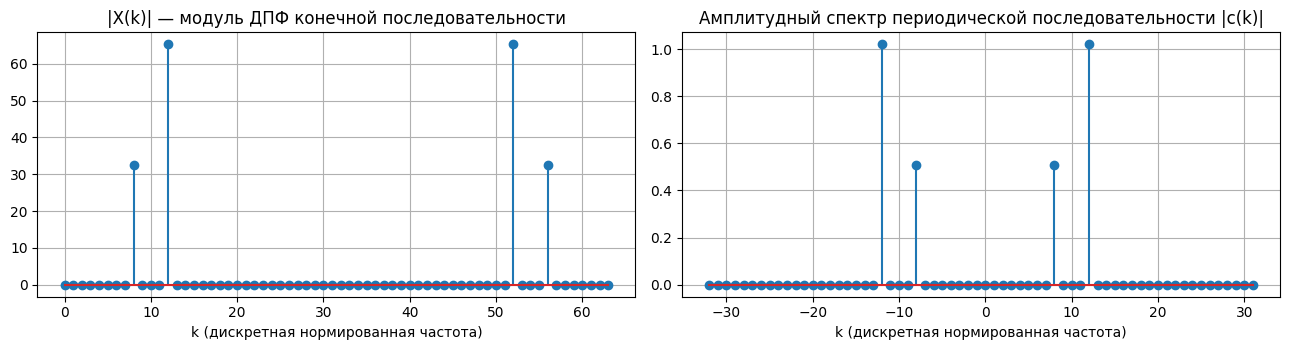

|X(k)| = N * |c(k)|: True
|X(8)| = 32.64000000000003 , |X(12)| = 65.27999999999999


In [62]:
X_fin = np.fft.fft(xs)                #

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].stem(k_idx, np.abs(X_fin)); ax[0].set_title('|X(k)| — модуль ДПФ конечной последовательности')
ax[0].set_xlabel('k (дискретная нормированная частота)')
ax[1].stem(k_c, amp); ax[1].set_title('Амплитудный спектр периодической последовательности |c(k)|')
ax[1].set_xlabel('k (дискретная нормированная частота)')
plt.tight_layout(); plt.show()

print('|X(k)| = N * |c(k)|:', np.allclose(np.abs(X_fin), N * np.abs(c)))
print('|X(8)| =', abs(X_fin[8]), ', |X(12)| =', abs(X_fin[12]))

**Пояснение: связь модуля ДПФ с амплитудным спектром.** ДПФ конечной последовательности длины $N$ совпадает по смыслу с ДПФ одного периода периодической последовательности: $X(k)=N\,c(k)$, т. е. $|X(k)|=N\,|c(k)|$.
То есть, форма графиков одинакова, различается только масштаб



#### Пункт 5.

Восстановить периодический аналоговый сигнал $x(t)$ по отсчетам ДПФ $X(k)$ периодической последовательности $x(n)$. Для вычисления значений сигнала $x(t)$ использовать формулу**

$$x(t)=\frac1N\sum_{k=-N/2}^{N/2-1}X_a(k)\exp\left(j\frac{2\pi}{NT}kt\right),$$

где отсчеты $X_a(k)$ связаны с отсчетами ДПФ $X(k)$ соотношением:

$$X_a(k)=\begin{cases}X(N+k), & -N/2\le k\le-1;\\ X(k), & 0\le k\le N/2-1,\end{cases}$$

задавая значения времени $t$ на интервале $t\in[0;(N-1)T]$ с шагом $\Delta t=0.25T$. Вывести графики:

>a. периодической последовательности $x(n)$ и модуля ее ДПФ;

>b. восстановленного аналогового сигнала $x(t)$ и его амплитудного спектра;

>c. исходного аналогового сигнала $x(t)=x(nT)\big|_{nT=t}$.

Число точек t: 253 , max |Im x(t)| = 3.133962166859495e-14


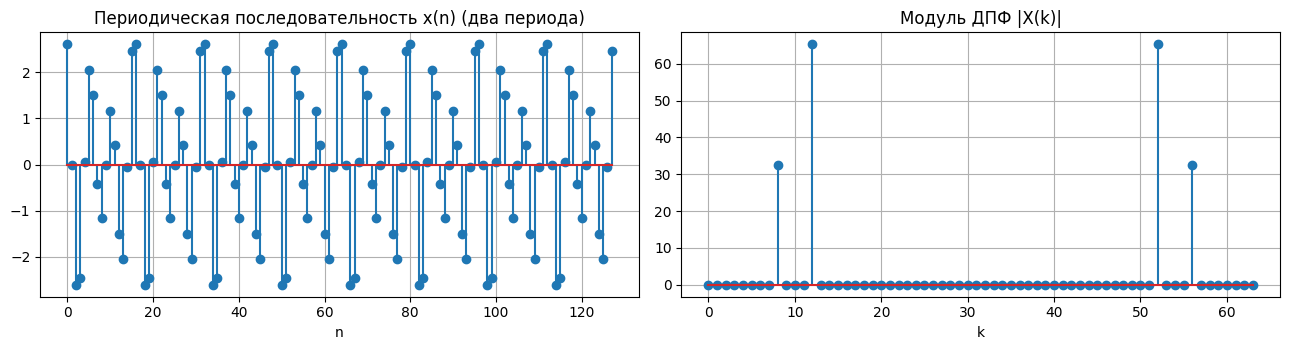

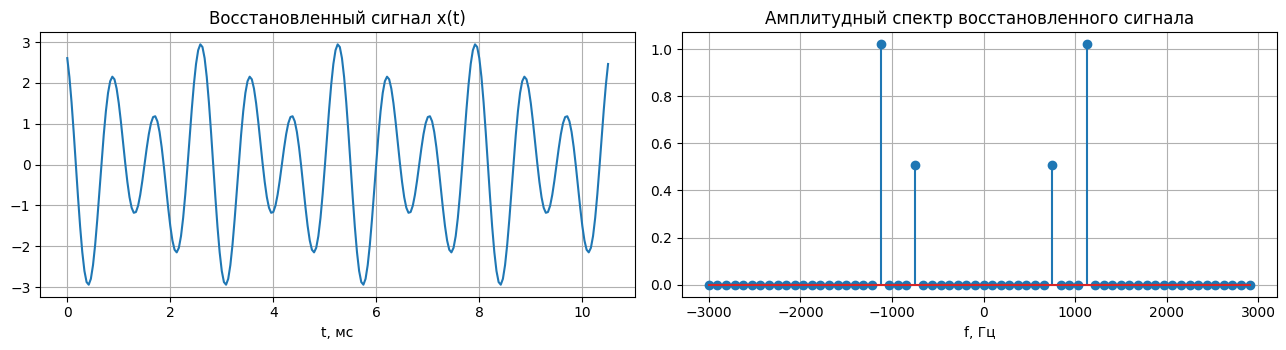

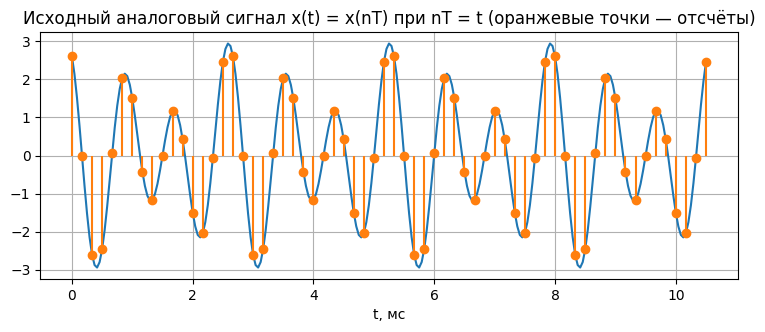

In [63]:
k_a = np.arange(-N // 2, N // 2)
Xa = np.concatenate([Xk[N // 2:], Xk[:N // 2]])

t = np.arange(4 * (N - 1) + 1) * 0.25 * T
x_t_rec = (Xa[:, None] * np.exp(2j * np.pi * k_a[:, None] * t[None, :] / (N * T))).sum(axis=0) / N
print('Число точек t:', len(t), ', max |Im x(t)| =', np.max(np.abs(x_t_rec.imag)))

x_t_orig = A1 * np.cos(2 * np.pi * f1 * t + np.pi / 4) + A2 * np.cos(2 * np.pi * f2 * t + np.pi / 8)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].stem(np.arange(2 * N), np.tile(xs, 2)); ax[0].set_title('Периодическая последовательность x(n) (два периода)'); ax[0].set_xlabel('n')
ax[1].stem(k_idx, np.abs(Xk)); ax[1].set_title('Модуль ДПФ |X(k)|'); ax[1].set_xlabel('k')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].plot(t * 1e3, x_t_rec.real); ax[0].set_title('Восстановленный сигнал x(t)'); ax[0].set_xlabel('t, мс')
ax[1].stem(k_a / (N * T), np.abs(Xa) / N); ax[1].set_title('Амплитудный спектр восстановленного сигнала')
ax[1].set_xlabel('f, Гц')
plt.tight_layout(); plt.show()

plt.plot(t * 1e3, x_t_orig)
plt.stem(n_idx * T * 1e3, xs, linefmt='C1-', markerfmt='C1o', basefmt=' ')
plt.title('Исходный аналоговый сигнал x(t) = x(nT) при nT = t (оранжевые точки — отсчёты)')
plt.xlabel('t, мс'); plt.show()

#### Пункт 6. Анализ результатов

> Исходя из результатов п. 5, объяснить:

> a. связь модуля ДПФ последовательности со спектром аналогового сигнала;

>b. результат визуального сравнения восстановленного и исходного сигналов.

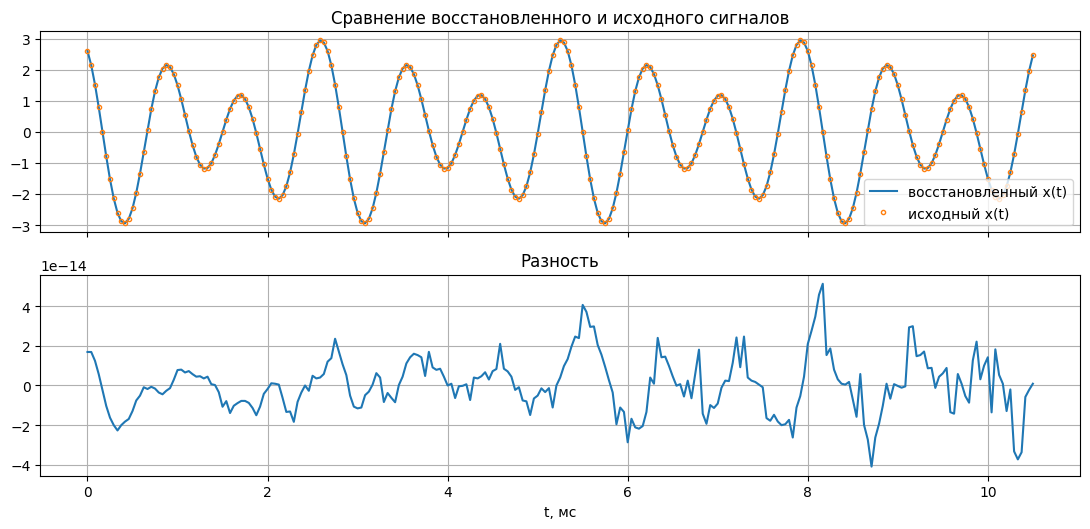

max |x_rec(t) - x(t)| = 5.124371399172827e-14


In [64]:
fig, ax = plt.subplots(2, 1, figsize=(11, 5.4), sharex=True)
ax[0].plot(t * 1e3, x_t_rec.real, label='восстановленный x(t)')
ax[0].plot(t * 1e3, x_t_orig, 'o', ms=3, mfc='none', label='исходный x(t)')
ax[0].legend(); ax[0].set_title('Сравнение восстановленного и исходного сигналов')
ax[1].plot(t * 1e3, x_t_rec.real - x_t_orig); ax[1].set_title('Разность'); ax[1].set_xlabel('t, мс')
plt.tight_layout(); plt.show()
print('max |x_rec(t) - x(t)| =', np.max(np.abs(x_t_rec.real - x_t_orig)))

**Пояснения.**

**a. Связь модуля ДПФ со спектром аналогового сигнала.** Величина $|X(k)|/N$ — амплитуда линии спектра периодического сигнала на частоте $f_k=k/(NT)=kf_s/N$. Поэтому модуль ДПФ с точностью до множителя $N$ и замены оси $k\to f=kf_s/N$ воспроизводит спектр аналогового сигнала.

**b. Визуальное сравнение восстановленного и исходного сигналов.**  Восстановленный и исходный сигналы визуально неразличимы, кривая восстановленного сигнала проходит через все нанесённые отсчётные точки


#### Пункт 7. Равенство Парсеваля

> Проверить равенство Парсеваля. Пояснить его смысл.

Для периодической последовательности с периодом $N$ равенство Парсеваля имеет вид $\sum_{n=0}^{N-1}|x(n)|^2=\frac1N\sum_{k=0}^{N-1}|X(k)|^2$.

In [65]:
E_time = np.sum(np.abs(xs) ** 2)
E_freq = np.sum(np.abs(Xk) ** 2) / N
E_theory = N * (A1 ** 2 + A2 ** 2) / 2

print(f'Σ|x(n)|²        = {E_time:.6f}')
print(f'(1/N)Σ|X(k)|²   = {E_freq:.6f}')
print(f'N(A1²+A2²)/2    = {E_theory:.6f}')
print('Равенство Парсеваля выполняется:', np.isclose(E_time, E_freq))

g1 = A1 * np.cos(2 * np.pi * f1 * n_idx * T + np.pi / 4)
g2 = A2 * np.cos(2 * np.pi * f2 * n_idx * T + np.pi / 8)
print(f'Σ g1² = {np.sum(g1**2):.4f}   (A1²·N/2 = {A1**2 * N / 2:.4f})')
print(f'Σ g2² = {np.sum(g2**2):.4f}  (A2²·N/2 = {A2**2 * N / 2:.4f})')
print(f'2·Σ g1·g2 = {2 * np.sum(g1 * g2):.2e}   (взаимная энергия)')
print(f'Средняя мощность (1/N)Σ|x|² = {E_time / N:.4f},   Σ|c(k)|² = {np.sum(np.abs(c) ** 2):.4f}')

Σ|x(n)|²        = 166.464000
(1/N)Σ|X(k)|²   = 166.464000
N(A1²+A2²)/2    = 166.464000
Равенство Парсеваля выполняется: True
Σ g1² = 33.2928   (A1²·N/2 = 33.2928)
Σ g2² = 133.1712  (A2²·N/2 = 133.1712)
2·Σ g1·g2 = 1.19e-13   (взаимная энергия)
Средняя мощность (1/N)Σ|x|² = 2.6010,   Σ|c(k)|² = 2.6010


**Пояснения.**

**Проверка.** Энергия на периоде во временной области и энергия по отсчётам ДПФ совпадают: $\sum|x(n)|^2=\frac1N\sum|X(k)|^2=166.464$. Множитель $1/N$ - нормирующий множитель.

**Аналитически.** Возведение в квадрат даёт три слагаемых:

$$
\sum_{n=0}^{N-1}x^2(n)=A_1^2\sum_n\cos^2(\cdot)+A_2^2\sum_n\cos^2(\cdot)+2A_1A_2\sum_n\cos(\cdot)\cos(\cdot).
$$

На периоде $N=64$ укладывается целое число периодов каждой гармоники ($8$ и $12$), поэтому $\sum_n\cos^2(\cdot)=N/2=32$, а взаимное слагаемое равно нулю. Итого $\frac N2(A_1^2+A_2^2)=33.293+133.171=166.464$ - совпадает с численным результатом. Для средней мощности получается $\frac1N\sum|x|^2=2.601=\sum_k|c(k)|^2=2\cdot0.51^2+2\cdot1.02^2$.

**Смысл равенства.** ДПФ — ортогональное преобразование, поэтому оно не меняет энергию сигнала. Величина $|X(k)|^2$ показывает вклад $k$-й гармоники в энергию последовательности, а сумма вкладов всех гармоник равна полной энергии во временной области.

## Выводы

В ходе выполнения работы исследовано рекурсивное звено 2-го порядка во временной и частотной областях и выполнен спектральный анализ периодической последовательности с помощью ДПФ.


**Часть 1.** Для рекурсивного звена 2-го порядка вычислена импульсная характеристика длиной $N_1=22$ отсчёта, результат совпал с аналитической формулой. Импульсная характеристика рекурсивного звена теоретически бесконечна, а число $N_1$ определяет только длину наблюдения. Реакции на прямоугольный импульс, рассчитанные по формуле свёртки и по разностному уравнению, совпадают при $n<N_1=22$ и расходятся начиная с $n=22$ из-за усечения импульсной характеристики до $N_1$ отсчётов.

Полюсы передаточной функции ($|p_{1,2}|=0.807$) лежат внутри единичной окружности, следовательно, звено устойчиво. Нули ($|z_{1,2}|=1.095$) лежат вне окружности и на устойчивость не влияют. АЧХ имеет максимум $4.0$ при $\hat\omega\approx0.689\pi$ вблизи частоты полюса ($0.671\pi$) и минимум $0.059$ при $\hat\omega\approx0.343\pi$ вблизи частоты нуля ($0.346\pi$). Так как нули не лежат на единичной окружности, нулей АЧХ и скачков ФЧХ на $\pi$ нет. Низкие частоты воздействия подавляются, высокие усиливаются.

**Часть 2.** Спектр содержит четыре линии ($k=\pm8$ и $k=\pm12$, т. е. $\pm750$ и $\pm1125$ Гц): высоты линий равны половинам амплитуд гармоник, $A_1/2=0.51$ и $A_2/2=1.02$, фазы равны начальным фазам $\pi/4$ и $\pi/8$, а линии при $k=-8$ и $k=-12$ являются зеркальными. Обратное ДПФ восстанавливает исходную последовательность. Модуль ДПФ конечной последовательности отличается от амплитудного спектра периодической последовательности только множителем $N=64$. Периодический аналоговый сигнал восстановлен по отсчётам ДПФ, восстановленный и исходный сигналы совпадают. Равенство Парсеваля выполняется: обе части равны $166.464$.